# Titanic

The target is a binary variable, indicating whether a person survived the sinking of the Titanic.
Other variables:
* PassengerId - unique identifier
* Pclass - ticket class; a proxy for socio-economic status (SES) (1 = Upper|2 = Middle|3 = Lower)
* Name - passenger's name
* Sex - sex (male/female)
* Age - age in years
* SibSp - number of siblings / spouses aboard the Titanic
* Parch - number of parents / children aboard the Titanic
* Ticket - ticket number
* Fare - passenger fare
* Cabin - cabin number
* Embarked - port of embarkation (C = Cherbourg|Q = Queenstown|S = Southampton)

## Import libraries

In [1]:
import torch

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, QuantileTransformer, StandardScaler

from config import config

## EDA

In [2]:
df = pd.read_csv(config.paths.path_to_dataset)
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


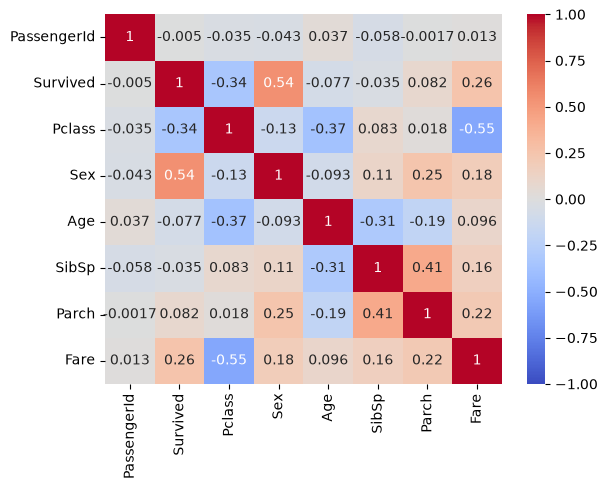

In [5]:
df_copy = df.copy()
df_copy.Sex = np.where(df_copy.Sex == 'male', 0, 1)
corr = df_copy.corr(numeric_only=True)
sns.heatmap(corr, vmin=-1, vmax=1, center=0, annot=True, cmap='coolwarm')
plt.show()

In [6]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
def get_deck(cabin):
    if type(cabin) == float:
        return 'Unknown'
    parts = cabin.split()
    if len(parts) == 1:
        return cabin[0]
    for part in parts:
        if len(part) > 1:
            return part[0]
    return 'Unknown'

df['Deck'] = df['Cabin'].apply(get_deck)
df['Surname'] = df['Name'].apply(lambda x: x[:x.find(',')])
df['Title'] = df['Name'].apply(lambda x: x[x.find(',')+2:x.find('.')])
df.loc[~df.Title.isin(['Mr', 'Miss', 'Mrs', 'Master']), 'Title'] = 'Rare'
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Deck,Surname,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Unknown,Braund,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,C,Cumings,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Unknown,Heikkinen,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,C,Futrelle,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Unknown,Allen,Mr


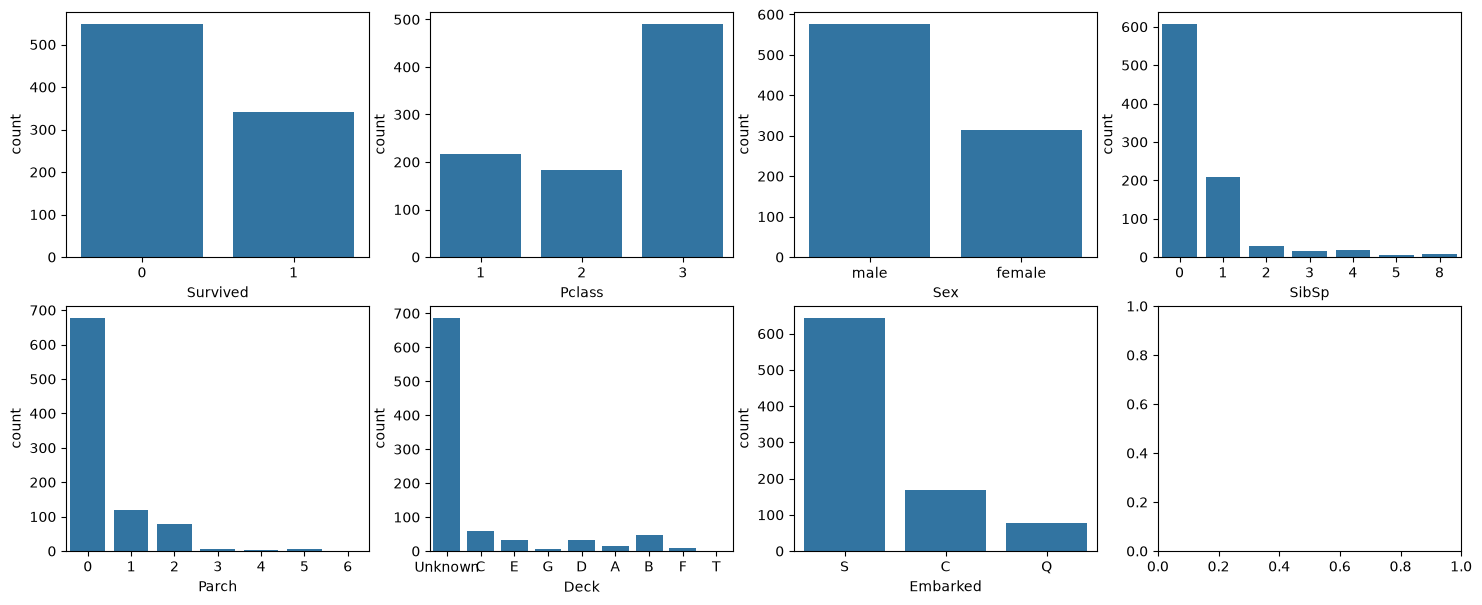

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
sns.countplot(df, ax=axes[0, 0],  x='Survived')
sns.countplot(df, ax=axes[0, 1],  x='Pclass')
sns.countplot(df, ax=axes[0, 2],  x='Sex')
sns.countplot(df, ax=axes[0, 3],  x='SibSp')
sns.countplot(df, ax=axes[1, 0],  x='Parch')
sns.countplot(df, ax=axes[1, 1],  x='Deck')
sns.countplot(df, ax=axes[1, 2],  x='Embarked')

plt.show()

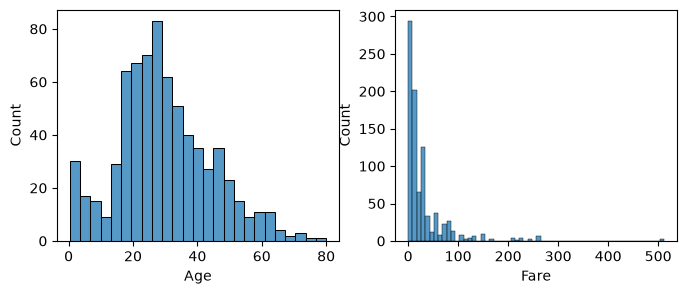

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
sns.histplot(df, ax=axes[0], x='Age', bins=25)
sns.histplot(df, ax=axes[1], x='Fare')
plt.show()

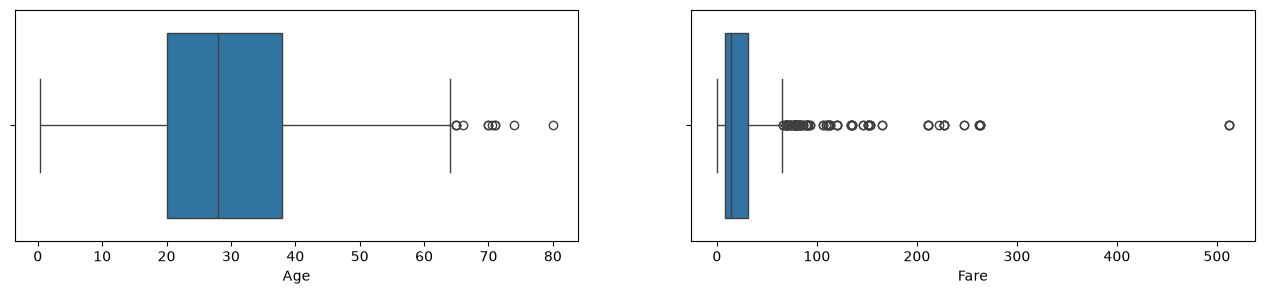

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3))
sns.boxplot(df, ax=axes[0], x='Age')
sns.boxplot(df, ax=axes[1], x='Fare')
plt.show()

In [11]:
is_eval_imputer = False
if is_eval_imputer:
    import time

    from sklearn.model_selection import KFold, train_test_split
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.experimental import enable_iterative_imputer
    from sklearn.impute import IterativeImputer
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.linear_model import BayesianRidge
    from sklearn.neighbors import KNeighborsRegressor
    from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

    from custom_transformers import GroupStatImputer, EstimatorImputer


    X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Deck', 'Title', 'IsGroupTicket']]
    y = df.Survived

    data: pd.DataFrame = train_test_split(
        X,
        y, 
        test_size=config.general.test_size, 
        random_state=config.general.seed,
        stratify=y
    )[0]
    data = data[data['Age'].notna()]
    age_true = data.Age

    cat_cols = ['Sex', 'Embarked', 'Deck', 'Title']
    num_cols = ['Fare', 'Parch', 'SibSp']
    splitter = KFold(n_splits=5, shuffle=True, random_state=42)
    group_oof_median = np.full(len(data), np.nan)
    group_oof_mean = np.full(len(data), np.nan)
    estimator_oof = np.full(len(data), np.nan)
    iterative_oof_1 = np.full(len(data), np.nan)
    iterative_oof_2 = np.full(len(data), np.nan)
    iterative_oof_3 = np.full(len(data), np.nan)

    estimator_imputer_times = []
    iterative_imputer_times = []

    def encode(ohe, X):
        encoded = pd.DataFrame(
            ohe.transform(X[cat_cols]),
            columns=ohe.get_feature_names_out(cat_cols),
            index=X.index,
        )
        return pd.concat([X.drop(columns=cat_cols), encoded], axis=1)

    for train_index, val_index in splitter.split(data):
        train = data.iloc[train_index]
        val = data.iloc[val_index]
        val['Age'] = np.nan

        # GroupStatImputer
        group_imputer_median = GroupStatImputer(target_col='Age', group_cols=['Title'], method='median')
        group_imputer_median.fit(train)
        group_oof_median[val_index] = group_imputer_median.transform(val)['Age'].to_numpy()

        group_imputer_mean = GroupStatImputer(target_col='Age', group_cols=['Title'], method='mean')
        group_imputer_mean.fit(train)
        group_oof_mean[val_index] = group_imputer_mean.transform(val)['Age'].to_numpy()

        # Feature preprocessing
        ohe = OneHotEncoder(drop='if_binary', handle_unknown='infrequent_if_exist', sparse_output=False, min_frequency=5)
        ohe.fit(train[cat_cols])
        train_encoded = encode(ohe, train)
        val_encoded = encode(ohe, val)

        ss = StandardScaler()
        ss.fit(train[num_cols])
        train_encoded[num_cols] = ss.transform(train_encoded[num_cols])
        val_encoded[num_cols] = ss.transform(val_encoded[num_cols])

        # EstimatorImputer
        start_time = time.time()
        estimator_imputer = EstimatorImputer(
            target_col='Age', 
            estimator=RandomForestRegressor(n_estimators=20, max_depth=5, max_samples=0.7, max_features=0.7, min_samples_leaf=3, random_state=42)
        )
        estimator_imputer.fit(train_encoded)
        estimator_oof[val_index] = estimator_imputer.transform(val_encoded)['Age'].to_numpy()
        estimator_imputer_times.append(time.time() - start_time)

        # IterativeImputer
        start_time = time.time()
        imputer_1 = IterativeImputer(
            estimator=RandomForestRegressor(n_estimators=20, max_depth=5, max_samples=0.7, max_features=0.7, min_samples_leaf=3, random_state=42),
            max_iter=1,
            random_state=42,
        ).set_output(transform='pandas')
        imputer_1.fit(train_encoded)
        iterative_oof_1[val_index] = imputer_1.transform(val_encoded)['Age'].to_numpy()
        iterative_imputer_times.append(time.time() - start_time)

        imputer_2 = IterativeImputer(
            estimator=BayesianRidge(),
            max_iter=1,
            random_state=42,
        ).set_output(transform='pandas')
        imputer_2.fit(train_encoded)
        iterative_oof_2[val_index] = imputer_2.transform(val_encoded)['Age'].to_numpy()

        imputer_3 = IterativeImputer(
            estimator=KNeighborsRegressor(n_neighbors=15),
            max_iter=1,
            random_state=42,
        ).set_output(transform='pandas')
        imputer_3.fit(train_encoded)
        iterative_oof_3[val_index] = imputer_3.transform(val_encoded)['Age'].to_numpy()

    global_median = np.full(len(age_true), age_true.median())
    print('global median', 'MAE', mean_absolute_error(age_true, global_median), 'RMSE', root_mean_squared_error(age_true, global_median), 'R2', r2_score(age_true, global_median), sep='\t')
    print('group median', 'MAE', mean_absolute_error(age_true, group_oof_median), 'RMSE', root_mean_squared_error(age_true, group_oof_median), 'R2', r2_score(age_true, group_oof_median), sep='\t')
    print('group mean', 'MAE', mean_absolute_error(age_true, group_oof_mean), 'RMSE', root_mean_squared_error(age_true, group_oof_mean), 'R2', r2_score(age_true, group_oof_mean), sep='\t')
    print('estimator', 'MAE', mean_absolute_error(age_true, estimator_oof), 'RMSE', root_mean_squared_error(age_true, estimator_oof), 'R2', r2_score(age_true, estimator_oof), sep='\t')
    print('iterative_1', 'MAE', mean_absolute_error(age_true, iterative_oof_1), 'RMSE', root_mean_squared_error(age_true, iterative_oof_1), 'R2', r2_score(age_true, iterative_oof_1), sep='\t')
    print('iterative_2', 'MAE', mean_absolute_error(age_true, iterative_oof_2), 'RMSE', root_mean_squared_error(age_true, iterative_oof_2), 'R2', r2_score(age_true, iterative_oof_2), sep='\t')
    print('iterative_3', 'MAE', mean_absolute_error(age_true, iterative_oof_3), 'RMSE', root_mean_squared_error(age_true, iterative_oof_3), 'R2', r2_score(age_true, iterative_oof_3), sep='\t')
    print(f'\nEstimatorImputer time: {np.mean(estimator_imputer_times)} | IterativeImputer time: {np.mean(iterative_imputer_times)}')

    result = pd.DataFrame({'true': age_true, 'global_median': global_median, 'group_median': group_oof_median, 'estimator': estimator_oof, 'iterative': iterative_oof_1, 'true_global_diff': np.abs(age_true - global_median)})
    print(result.head(15))

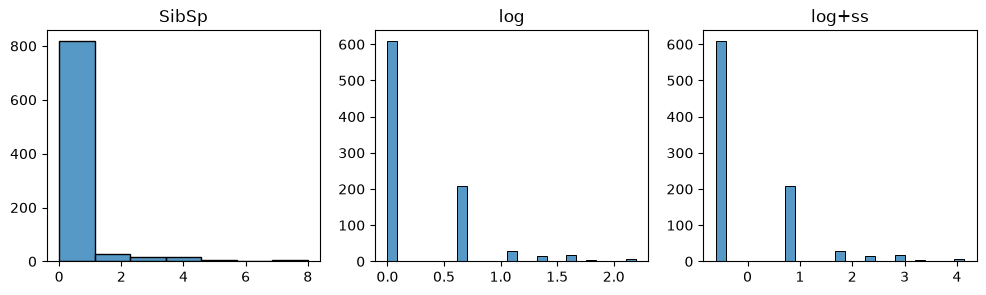

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

ft = FunctionTransformer(np.log1p)
ss = StandardScaler()

sibsp_ft = ft.transform(df.SibSp)
sibsp_ss = ss.fit_transform(pd.DataFrame(sibsp_ft))

sns.histplot(df.SibSp.values, ax=axes[0], bins=7).set_title('SibSp')
sns.histplot(sibsp_ft.values, ax=axes[1], bins=25).set_title('log')
sns.histplot(sibsp_ss[:, 0], ax=axes[2], bins=25).set_title('log+ss')


for ax in axes:
    ax.set_ylabel('')
plt.show()

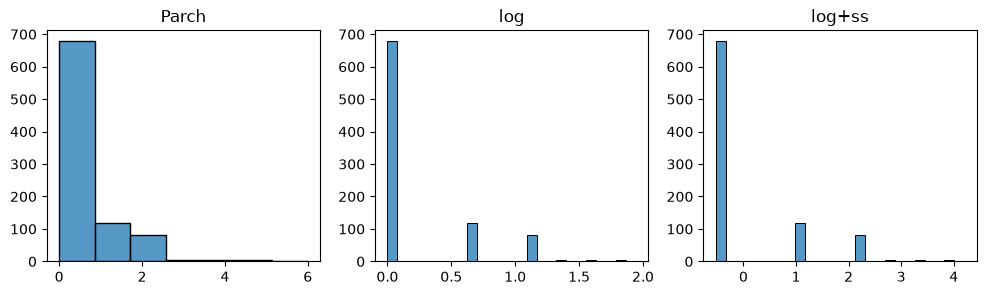

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

ft = FunctionTransformer(np.log1p)
ss = StandardScaler()

parch_ft = ft.transform(df.Parch)
parch_ss = ss.fit_transform(pd.DataFrame(parch_ft))

sns.histplot(df.Parch.values, ax=axes[0], bins=7).set_title('Parch')
sns.histplot(parch_ft.values, ax=axes[1], bins=25).set_title('log')
sns.histplot(parch_ss[:, 0], ax=axes[2], bins=25).set_title('log+ss')


for ax in axes:
    ax.set_ylabel('')
plt.show()

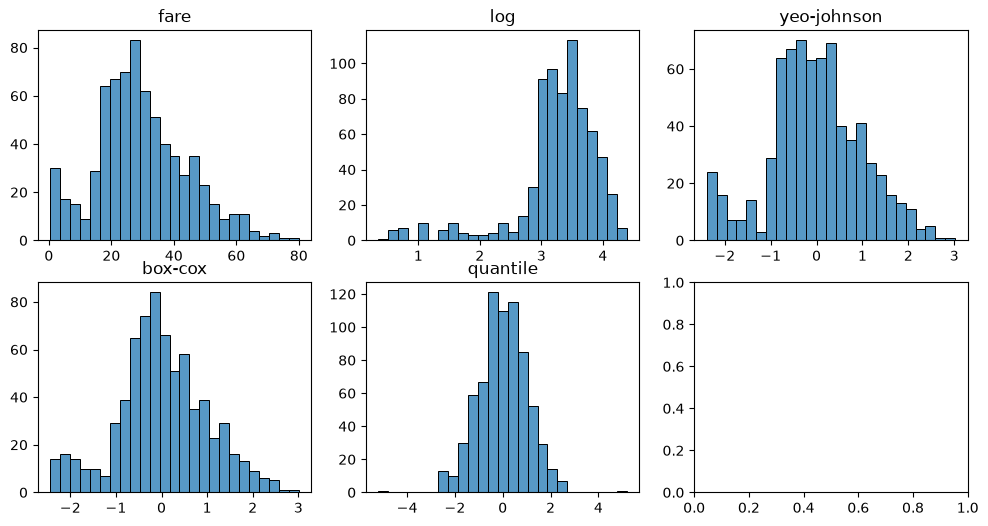

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))

ft = FunctionTransformer(np.log1p)
yj = PowerTransformer(method='yeo-johnson')
bc = PowerTransformer(method='box-cox')
qt = QuantileTransformer(n_quantiles=100, output_distribution='normal', random_state=42)

age_ft = ft.transform(df.Age)
age_yj = yj.fit_transform(df[['Age']])
age_bc = bc.fit_transform(df[['Age']])
age_qt = qt.fit_transform(df[['Age']])

sns.histplot(df.Age.values, ax=axes[0, 0], bins=25).set_title('fare')
sns.histplot(age_ft.values, ax=axes[0, 1], bins=25).set_title('log')
sns.histplot(age_yj[:, 0], ax=axes[0, 2], bins=25).set_title('yeo-johnson')
sns.histplot(age_bc[:, 0], ax=axes[1, 0], bins=25).set_title('box-cox')
sns.histplot(age_qt[:, 0], ax=axes[1, 1], bins=25).set_title('quantile')

for row in axes:
    for ax in row:
        ax.set_ylabel('')
plt.show()

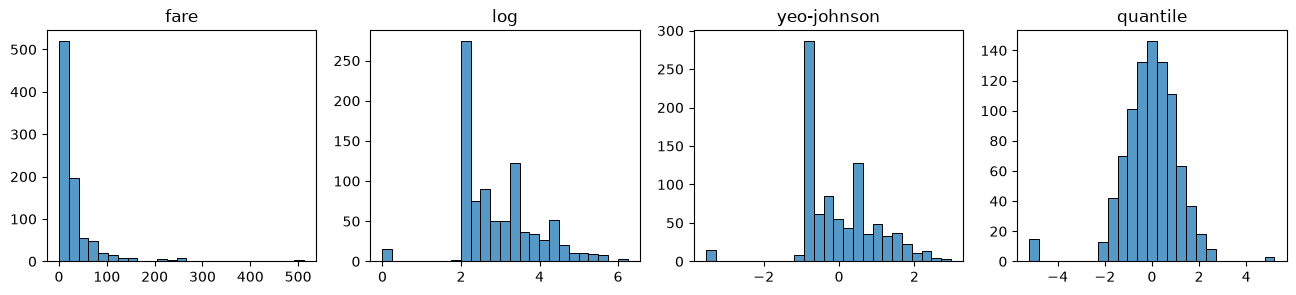

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))

ft = FunctionTransformer(np.log1p)
yj = PowerTransformer(method='yeo-johnson')
qt = QuantileTransformer(n_quantiles=100, output_distribution='normal', random_state=42)

fare_ft = ft.transform(df.Fare)
fare_yj = yj.fit_transform(df[['Fare']])
fare_qt = qt.fit_transform(df[['Fare']])

sns.histplot(df.Fare.values, ax=axes[0], bins=25).set_title('fare')
sns.histplot(fare_ft.values, ax=axes[1], bins=25).set_title('log')
sns.histplot(fare_yj[:, 0], ax=axes[2], bins=25).set_title('yeo-johnson')
sns.histplot(fare_qt[:, 0], ax=axes[3], bins=25).set_title('quantile')

for ax in axes:
    ax.set_ylabel('')
plt.show()

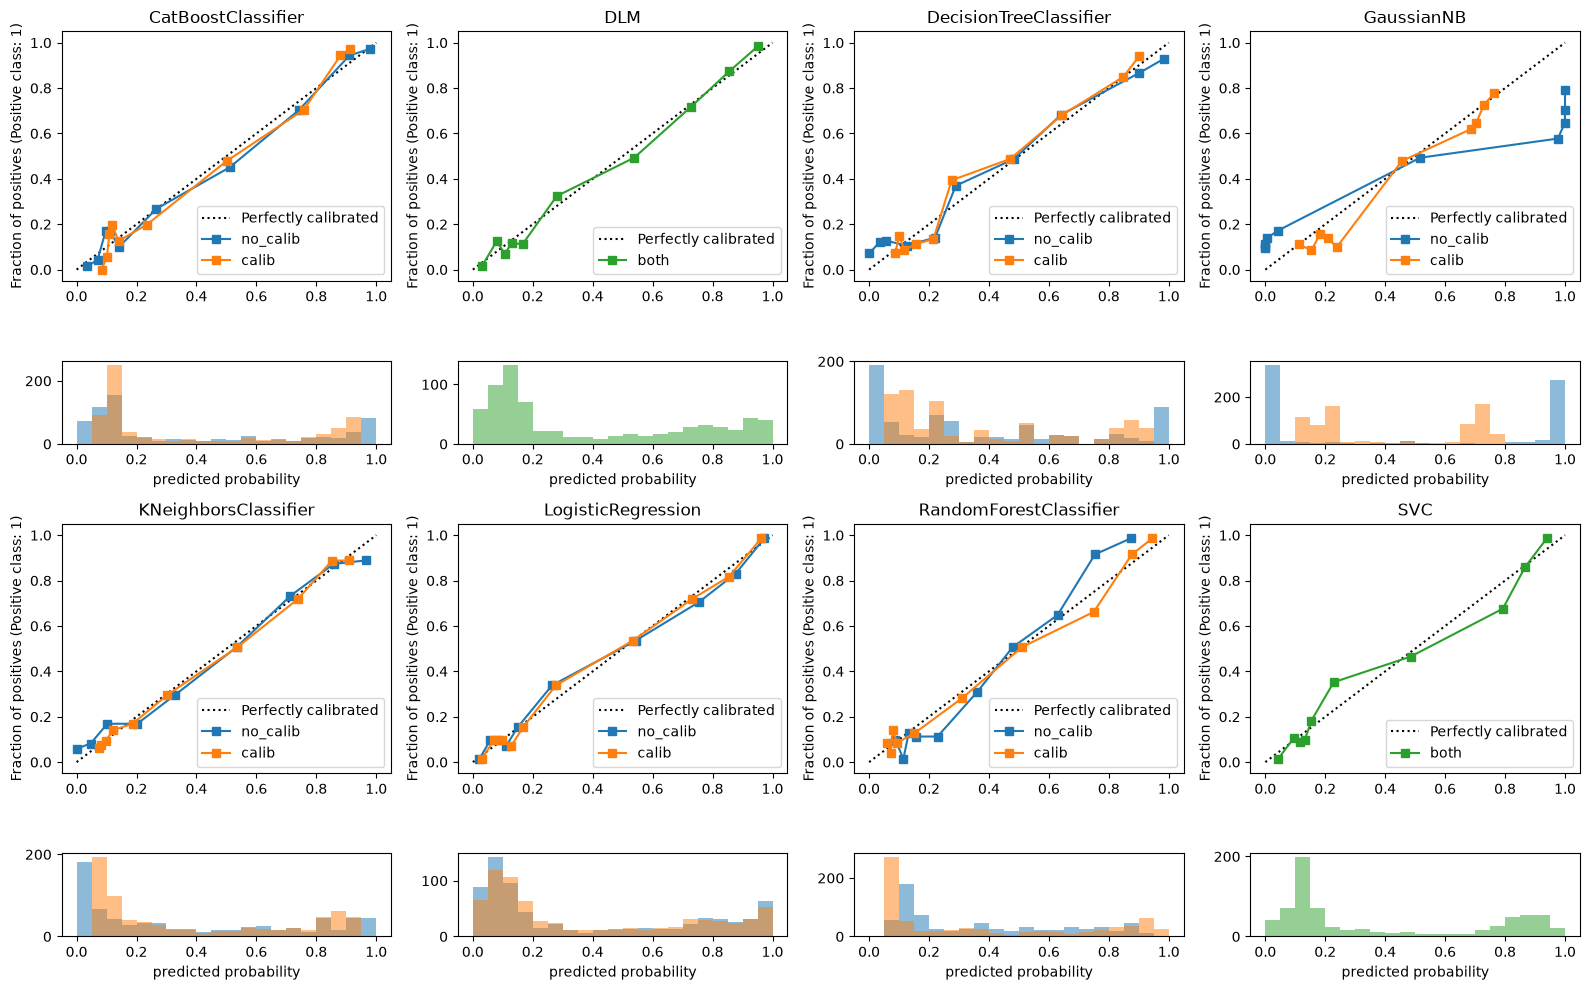

brier  log_loss  calibration_slope  \
model                  run                                             
CatBoostClassifier     no_calib  0.1142    0.3718             0.9786   
                       calib     0.1155    0.3790             1.1195   
DLM                    both      0.1181    0.3795             1.0721   
DecisionTreeClassifier no_calib  0.1446    0.5668             0.4680   
                       calib     0.1428    0.4500             1.0421   
GaussianNB             no_calib  0.2106    1.7764             0.1352   
                       calib     0.1658    0.5088             1.0776   
KNeighborsClassifier   no_calib  0.1334    0.5843             0.3433   
                       calib     0.1317    0.4224             1.0117   
LogisticRegression     no_calib  0.1201    0.3860             0.9348   
                       calib     0.1199    0.3855             1.0254   
RandomForestClassifier no_calib  0.1253    0.4097             1.4479   
                       calib     0.1203    0.3892             1.0055   
SVC                    both      0.1242    0.3975             0.9957   

                                 mean_pred  base_rate  
model                  run                             
CatBoostClassifier     no_calib     0.3864     0.3834  
                       calib        0.3842     0.3834  
DLM                    both         0.3868     0.3834  
DecisionTreeClassifier no_calib     0.3660     0.3834  
                       calib        0.3754     0.3834  
GaussianNB             no_calib     0.4540     0.3834  
                       calib        0.4233     0.3834  
KNeighborsClassifier   no_calib     0.3748     0.3834  
                       calib        0.3899     0.3834  
LogisticRegression     no_calib     0.3839     0.3834  
                       calib        0.3857     0.3834  
RandomForestClassifier no_calib     0.3820     0.3834  
                       calib        0.3852     0.3834  
SVC                    both         0.3853     0.3834

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import logit
from sklearn.calibration import CalibrationDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss


def _calibration_slope(y: np.ndarray, p: np.ndarray) -> float:
    z = logit(np.clip(p, 1e-6, 1 - 1e-6)).reshape(-1, 1)
    return float(LogisticRegression(C=np.inf).fit(z, y).coef_[0, 0])


def _prob_metrics(y: np.ndarray, p: np.ndarray) -> dict[str, float]:
    return {
        'brier': brier_score_loss(y, p),
        'log_loss': log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)),
        'calibration_slope': _calibration_slope(y, p),
        'mean_pred': p.mean(),
        'base_rate': y.mean(),
    }


def plot_calibration_comparison(
    path_to_oof_uncalibrated: str,
    path_to_oof_calibrated: str,
    n_bins: int = 10,
    ncols: int = 4,
    exclude: tuple = ('ensemble',),
) -> pd.DataFrame:
    runs = {
        'no_calib': pd.read_csv(path_to_oof_uncalibrated, index_col=0),
        'calib': pd.read_csv(path_to_oof_calibrated, index_col=0),
    }
    a, b = runs['no_calib'], runs['calib']
    if not (a.index.equals(b.index) and a['target'].equals(b['target'])):
        raise ValueError('OOF files have different rows or targets: runs are not comparable (different split/seed?)')
    y = a['target'].to_numpy()

    models = sorted({c for df in runs.values() for c in df.columns} - {'target', *exclude})
    nrows = int(np.ceil(len(models) / ncols))
    fig, axes = plt.subplots(2 * nrows, ncols, figsize=(4 * ncols, 5 * nrows),
                             gridspec_kw={'height_ratios': [3, 1] * nrows}, squeeze=False)
    colors = {'no_calib': 'tab:blue', 'calib': 'tab:orange', 'both': 'tab:green'}

    rows = []
    for j, model in enumerate(models):
        ax_curve, ax_hist = axes[(j // ncols) * 2, j % ncols], axes[(j // ncols) * 2 + 1, j % ncols]

        preds = {run: df[model].to_numpy() for run, df in runs.items() if model in df.columns}
        if len(preds) == 2 and np.allclose(preds['no_calib'], preds['calib']):
            preds = {'both': preds['no_calib']}

        for k, (run, p) in enumerate(preds.items()):
            CalibrationDisplay.from_predictions(
                y, p, n_bins=n_bins, strategy='quantile', name=run, ref_line=(k == 0),
                ax=ax_curve, color=colors[run],
            )
            ax_hist.hist(p, bins=20, range=(0, 1), alpha=0.5, color=colors[run], label=run)
            rows.append({'model': model, 'run': run, **_prob_metrics(y, p)})

        ax_curve.set_title(model)
        ax_curve.set_xlabel('')
        ax_hist.set_xlabel('predicted probability')

    for j in range(len(models), nrows * ncols):
        axes[(j // ncols) * 2, j % ncols].axis('off')
        axes[(j // ncols) * 2 + 1, j % ncols].axis('off')

    fig.tight_layout()
    plt.show()
    return pd.DataFrame(rows).set_index(['model', 'run']).round(4)


plot_calibration_comparison(
    r'checkpoints\hyperparameterswoc\oof.csv',
    r'checkpoints\hyperparameterswc\oof.csv'
)

- SVC\
  Модель переуверенна, использует весь диапазон значений, метрики приемлемые - использовать с калибровкой
- LogisticRegression\
  Не значительное отличие, используют весь диапазон значений, метрики приемлемые - использовать без калибровки
- KNeighborsClassifier\
  Схожие графики, с калибровкой модель не использует крайние значений но метрики значительно лучше - использовать с калибровкой
- GaussianNB\
  Калибровка не достаточно стягивает от крайних значений, с калибровкой систематический сдвиг вероятности - использовать с калибровкой либо не использовать
- DecisionTreeClassifier\
  Схожие графики, с калибровкой модель не использует крайние значений но метрики значительно лучше - использовать с калибровкой
- RandomForestClassifier\
  Без калибровки переуверенна, калибровка почти идеально исправляет - использовать с калибровкой
- CatBoostClassifier\
  Схожие графики, калибровка немного портит метрики - использовать без калибровки
- DLM\
  Хороший график и метрики - использовать без калибровки

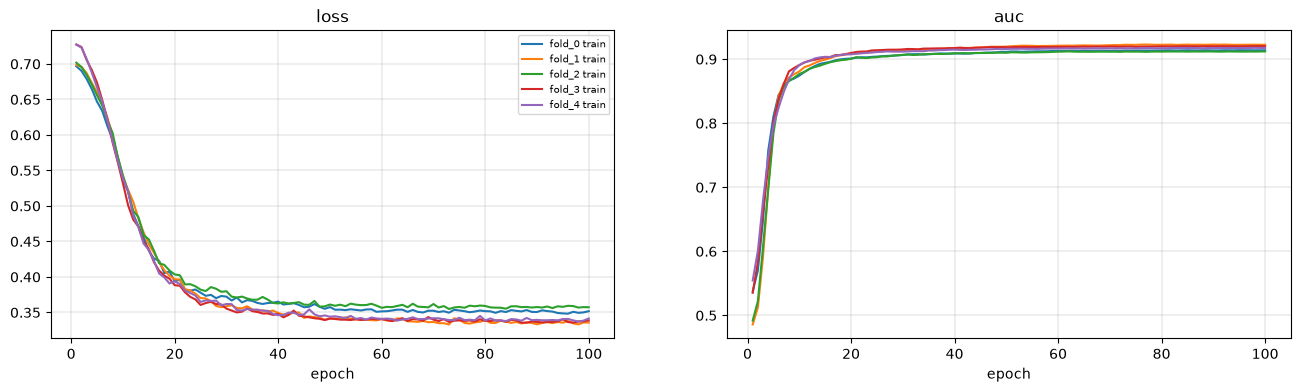

In [47]:
import glob

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for path in sorted(glob.glob('checkpoints/hyperparameters/models/DLM/fold_*/history.csv')):
    h = pd.read_csv(path)
    fold = path.split('\\')[-2]
    if (
        '0' in fold or 
        '1' in fold or 
        '2' in fold or
        '3' in fold or
        '4' in fold or
    False):
        for ax, metric in zip(axes, ['loss', 'auc']):
            line, = ax.plot(h['epoch'], h[f'train_{metric}'], label=f'{fold} train')
            if f'val_{metric}' in h:
                ax.plot(h['epoch'], h[f'val_{metric}'], linestyle='--', color=line.get_color(), label=f'{fold} val')
    
for ax, metric in zip(axes, ['loss', 'auc']):
    ax.set_title(metric); ax.set_xlabel('epoch')
    ax.grid(True, linewidth=0.3)
axes[0].legend(fontsize=7)
plt.show()


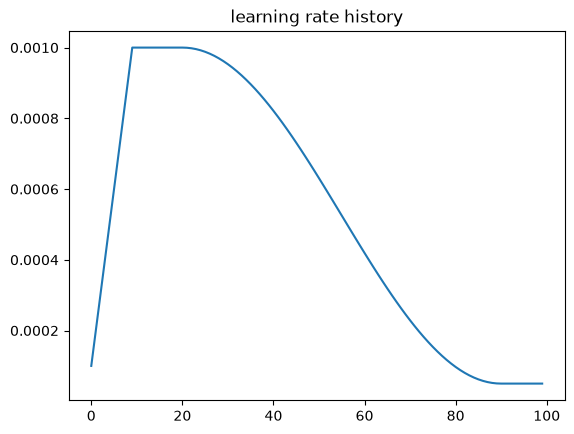

In [51]:
lr = pd.read_csv(r'checkpoints\hyperparameters\models\DLM\fold_0\history.csv').lr
plt.plot(lr)
plt.title('learning rate history')
plt.show()

In [52]:
import itertools
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score


def model_agreement(path_to_oof: str, threshold: float = 0.5, exclude: tuple = ('ensemble',)) -> dict[str, pd.DataFrame]:
    oof = pd.read_csv(path_to_oof, index_col=0)
    y = oof['target'].to_numpy()
    probs = oof[[c for c in oof.columns if c != 'target' and c not in exclude]]

    residuals = probs.sub(y, axis=0)
    wrong = (probs >= threshold).astype(int).ne(y, axis=0)

    rows = []
    for a, b in itertools.combinations(probs.columns, 2):
        pa, pb = probs[a].to_numpy(), probs[b].to_numpy()
        rows.append({
            'pair': f'{a} | {b}',
            'disagreement': float((wrong[a] != wrong[b]).mean()),
            'both_wrong': float((wrong[a] & wrong[b]).mean()),
            'auc_best_single': max(roc_auc_score(y, pa), roc_auc_score(y, pb)),
            'auc_pair_mean': roc_auc_score(y, (pa + pb) / 2),
        })
    pairs = pd.DataFrame(rows).set_index('pair')
    pairs['auc_gain'] = pairs['auc_pair_mean'] - pairs['auc_best_single']

    return {
        'spearman_probs': probs.corr(method='spearman').round(3),
        'pearson_residuals': residuals.corr().round(3),
        'pairs': pairs.round(4).sort_values('auc_gain', ascending=False),
    }

a = model_agreement(r'checkpoints\hyperparameters\oof.csv')

In [53]:
a['spearman_probs']

,SVC,LogisticRegression,KNeighborsClassifier,GaussianNB,DecisionTreeClassifier,RandomForestClassifier,CatBoostClassifier,DLM
SVC,1.000,0.960,0.823,0.712,0.843,0.878,0.917,0.965
LogisticRegression,0.960,1.000,0.814,0.741,0.847,0.890,0.917,0.988
KNeighborsClassifier,0.823,0.814,1.000,0.667,0.795,0.843,0.840,0.835
GaussianNB,0.712,0.741,0.667,1.000,0.728,0.811,0.754,0.730
DecisionTreeClassifier,0.843,0.847,0.795,0.728,1.000,0.871,0.854,0.848
RandomForestClassifier,0.878,0.890,0.843,0.811,0.871,1.000,0.911,0.888
CatBoostClassifier,0.917,0.917,0.840,0.754,0.854,0.911,1.000,0.926
DLM,0.965,0.988,0.835,0.730,0.848,0.888,0.926,1.000


Пары моделей со высокими метриками которые по разному ранжируют:
- CatBoostClassifier + DLM
- CatBoostClassifier + LogisticRegression
- CatBoostClassifier + SVC

In [23]:
a['pearson_residuals']

,SVC,LogisticRegression,KNeighborsClassifier,GaussianNB,DecisionTreeClassifier,RandomForestClassifier,CatBoostClassifier,DLM
SVC,1.000,0.963,0.899,0.822,0.929,0.967,0.945,0.968
LogisticRegression,0.963,1.000,0.912,0.837,0.911,0.957,0.946,0.995
KNeighborsClassifier,0.899,0.912,1.000,0.837,0.881,0.911,0.906,0.926
GaussianNB,0.822,0.837,0.837,1.000,0.865,0.871,0.840,0.856
DecisionTreeClassifier,0.929,0.911,0.881,0.865,1.000,0.928,0.904,0.923
RandomForestClassifier,0.967,0.957,0.911,0.871,0.928,1.000,0.963,0.966
CatBoostClassifier,0.945,0.946,0.906,0.840,0.904,0.963,1.000,0.957
DLM,0.968,0.995,0.926,0.856,0.923,0.966,0.957,1.000


Пары моделей со схожими метриками которые ошибаются на разных данных:
- DLM + CatBoostClassifier
- CatBoostClassifier + SVC
- CatBoostClassifier + LogisticRegression
- KNeighborsClassifier + SVC

In [24]:
a['pairs']

,disagreement,both_wrong,auc_best_single,auc_pair_mean,auc_gain
pair,,,,,
KNeighborsClassifier | DecisionTreeClassifier,0.1419,0.1194,0.8744,0.8791,0.0047
SVC | KNeighborsClassifier,0.0997,0.1222,0.8918,0.8959,0.0041
LogisticRegression | CatBoostClassifier,0.0702,0.1292,0.8984,0.9021,0.0037
CatBoostClassifier | DLM,0.0660,0.1306,0.8989,0.9022,0.0034
SVC | LogisticRegression,0.0463,0.1404,0.8959,0.8984,0.0025
SVC | CatBoostClassifier,0.0576,0.1334,0.8984,0.9007,0.0023
SVC | RandomForestClassifier,0.0449,0.1447,0.8918,0.8938,0.0020
KNeighborsClassifier | RandomForestClassifier,0.1025,0.1264,0.8885,0.8904,0.0019
KNeighborsClassifier | CatBoostClassifier,0.0843,0.1306,0.8984,0.9002,0.0018


Пары моделей со высокими метриками которые вместе сильнее:
- SVC | KNeighborsClassifier
- LogisticRegression | CatBoostClassifier
- CatBoostClassifier | DLM
- SVC | LogisticRegression
- SVC | CatBoostClassifier
- SVC | RandomForestClassifier
- KNeighborsClassifier | CatBoostClassifier
- LogisticRegression | KNeighborsClassifier